In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [4]:
df = pd.read_csv("CarPrice_Assignment.csv")
print(df.shape)
print(df.isnull().sum().sum(), "missing values")
df.head()

(205, 26)
0 missing values


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [5]:
df = df.drop(columns=["car_ID"])
df["brand"] = df["CarName"].str.split().str[0].str.lower()
df["brand"] = df["brand"].replace({
    "maxda": "mazda", "porcshce": "porsche", "toyouta": "toyota",
    "vokswagen": "volkswagen", "vw": "volkswagen"
})
df = df.drop(columns=["CarName"])

X = df.drop(columns=["price"])
y = df["price"]

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [7]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), cat_cols),
])


In [8]:
lin = Pipeline([("prep", preprocess), ("model", LinearRegression())])

ridge_grid = GridSearchCV(
    Pipeline([("prep", preprocess), ("model", Ridge())]),
    param_grid={"model__alpha": np.logspace(-2, 3, 30)},
    cv=5, scoring="neg_mean_squared_error"
)

lasso_grid = GridSearchCV(
    Pipeline([("prep", preprocess), ("model", Lasso(max_iter=100000))]),
    param_grid={"model__alpha": np.logspace(-1, 3, 30)},
    cv=5, scoring="neg_mean_squared_error"
)

lin.fit(X_train, y_train)
ridge_grid.fit(X_train, y_train)
lasso_grid.fit(X_train, y_train)

ridge = ridge_grid.best_estimator_
lasso = lasso_grid.best_estimator_

print("Best Ridge alpha:", ridge_grid.best_params_["model__alpha"])
print("Best Lasso alpha:", lasso_grid.best_params_["model__alpha"])

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [8, 9] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown ca

Best Ridge alpha: 0.529831690628371
Best Lasso alpha: 22.12216291070448


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [8, 9] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown ca

In [9]:
def evaluate(model, Xa, ya):
    pred = model.predict(Xa)
    mse = mean_squared_error(ya, pred)
    return {
        "MAE": mean_absolute_error(ya, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(ya, pred),
    }

models = {"Linear": lin, "Ridge": ridge, "Lasso": lasso}

test_results = pd.DataFrame({n: evaluate(m, X_test, y_test) for n, m in models.items()}).T
train_results = pd.DataFrame({n: evaluate(m, X_train, y_train) for n, m in models.items()}).T

print("\n=== TEST SET COMPARISON ===")
print(test_results.round(3))
print("\n=== TRAIN SET (for overfitting check) ===")
print(train_results.round(3))

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(



=== TEST SET COMPARISON ===
             MAE          MSE      RMSE     R2
Linear  1763.566  7128546.784  2669.934  0.910
Ridge   1898.727  7616824.278  2759.859  0.904
Lasso   2143.800  8934169.172  2989.008  0.887

=== TRAIN SET (for overfitting check) ===
             MAE          MSE      RMSE     R2
Linear   910.133  1508602.667  1228.252  0.975
Ridge   1008.429  1780235.930  1334.255  0.970
Lasso   1216.960  2547628.106  1596.129  0.957



Lasso zeroed-out features: 26 of 63

Top 15 features by |Linear coef|:
                            Linear   Ridge   Lasso
cat__enginelocation_rear    8055.6  5561.7  8388.3
cat__cylindernumber_twelve -6143.1 -2502.1    -0.0
cat__brand_bmw              5392.0  5153.2  4936.6
cat__brand_dodge           -5179.3 -2298.4  -207.3
cat__brand_mitsubishi      -5176.5 -2418.1 -1009.6
cat__brand_plymouth        -5105.1 -2298.5  -414.5
cat__brand_subaru          -5042.6 -3148.5  -706.7
cat__enginetype_dohcv      -4933.6 -1433.1    -0.0
cat__brand_chevrolet       -4383.7 -1306.5     0.0
cat__cylindernumber_five   -3929.6 -1583.4     0.0
num__enginesize             3873.9  3552.4  3000.1
cat__cylindernumber_six    -3842.2 -1550.1    -0.0
cat__brand_toyota          -3670.2 -2100.0 -1268.3
cat__brand_mercury         -3557.6 -1322.5    -0.0
cat__brand_renault         -3525.6 -1398.8    -0.0


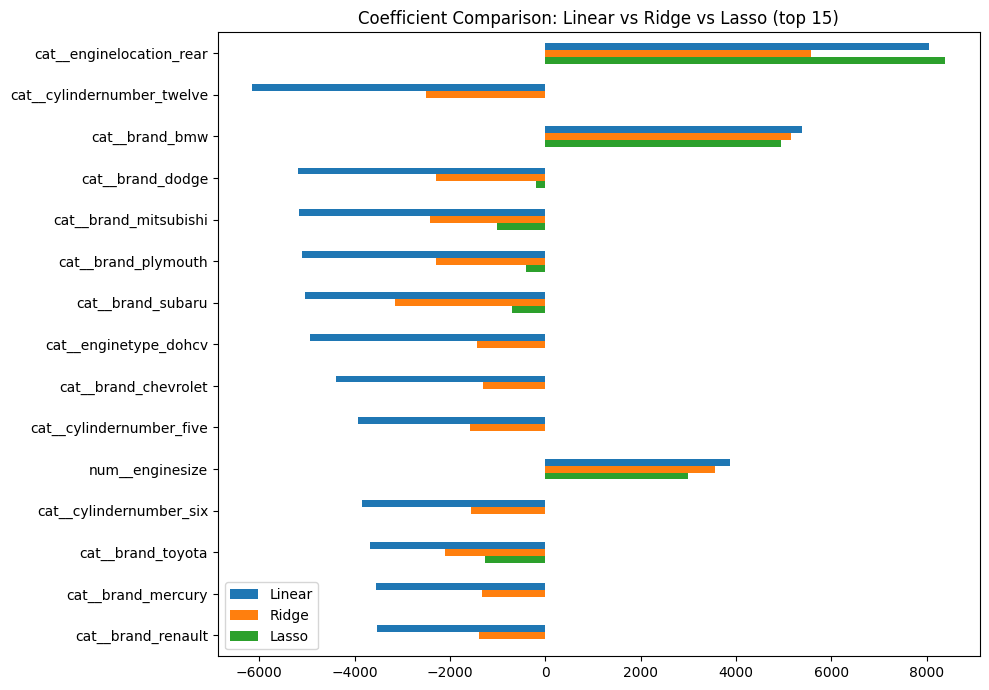


Sum of |coefficients|:
Linear    150841.1
Ridge      93559.6
Lasso      51034.3
dtype: float64


In [10]:
feature_names = lin.named_steps["prep"].get_feature_names_out()

coef_df = pd.DataFrame({
    "Linear": lin.named_steps["model"].coef_,
    "Ridge": ridge.named_steps["model"].coef_,
    "Lasso": lasso.named_steps["model"].coef_,
}, index=feature_names)

print("\nLasso zeroed-out features:", (coef_df["Lasso"] == 0).sum(), "of", len(coef_df))
print("\nTop 15 features by |Linear coef|:")
print(coef_df.reindex(coef_df["Linear"].abs().sort_values(ascending=False).index).head(15).round(1))

# Coefficient magnitude comparison plot
top = coef_df.reindex(coef_df["Linear"].abs().sort_values(ascending=False).index).head(15)
top.plot(kind="barh", figsize=(10, 7))
plt.title("Coefficient Comparison: Linear vs Ridge vs Lasso (top 15)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Shrinkage summary
print("\nSum of |coefficients|:")
print(coef_df.abs().sum().round(1))

In [11]:
best = test_results["RMSE"].idxmin()
print(f"\nBest generalizing model (lowest test RMSE): {best}")



Best generalizing model (lowest test RMSE): Linear


CONCLUSION:
Plain Linear Regression fits the training data very well but is prone to overfitting here,
because many features are correlated (curbweight, enginesize, carlength, horsepower, etc.)
and one-hot brand dummies add dimensionality on only 205 rows. Ridge shrinks the correlated
coefficients and stabilizes them, while Lasso additionally drives weak features to exactly zero,
giving a sparser, more interpretable model. The model with the lowest test RMSE and highest
test R2 (see table above) generalizes best, and the gap between train and test error shows
how much regularization reduced overfitting.